# Forest Cover Predictions Using Decision Tree, Random Forest, and SVM Models
Stephanie Gillihan | CSPB 4622 Machine Learning | Fall 2026

---

### Background and Overview
This project compares three supervised machine learning models (Decision Tree, Random Forest, and Support Vector Machine) to predict forest cover type using geographic and environmental data from the UCI Forest Covertype dataset. The main goal is to compare how well the models perform and to understand the strengths and weaknesses of each approach.

The project will begin with exploratory data analysis and basic data preparation. Next, each model will be tested with a small set of hyperparameter values to see how those settings affect performance and to choose reasonable starting values. The models will then be evaluated across repeated stratified random samples so their accuracy, stability, and consistency can be compared. Based on those results, the models will be fine-tuned and tested again. The final section will compare overall performance, training time, interpretability, and the practical tradeoffs between the three models.

#### Dataset Citation
Blackard, J. (1998). Covertype [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C50K5N.

#### Table of Contents
(TO-DO)


---

## Section I: Data Set-up, Exploratory Data Analysis, and Project Design

This section will import all required libraries for the project, process the zipped data, and set up functions for selecting startified random samples. This section will also include Exploratory Data Analysis (EDA). EDA summarizes the data in tabular or graphical form so the user can have a better understanding of features, value ranges, data formats, etc. Finally, this section will layout the project design.

In [16]:
# Import all necessary libraries

# general
import time               # used to time how long each model takes to train and predict
import zipfile            # the raw data is zipped, so this reads it without extracting it first
from pathlib import Path  # builds file paths that work on Windows, Mac, and Linux

# Data/Plotting
import numpy as np                 # numeric arrays
import pandas as pd                # DataFrames for holding data and results
import matplotlib.pyplot as plt    # base plotting library
import seaborn as sns              # additional plots

# scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV # cross-validation and hyperparameter tuning
from sklearn.dummy import DummyClassifier           # majority-class baseline
from sklearn.tree import DecisionTreeClassifier     # Decision Tree (also the simple baseline model)
from sklearn.ensemble import RandomForestClassifier # Random Forest
from sklearn.svm import SVC                         # Support Vector Machine
from sklearn.preprocessing import StandardScaler    # SVM needs features on the same scale
from sklearn.pipeline import Pipeline               # keeps scaling and the model together
from sklearn.metrics import (                       # evaluation metrics
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.feature_selection import mutual_info_classif   # feature selection
from sklearn.inspection import permutation_importance       # permutation importance

# One fixed random seed is used as the starting point everywhere so that the results can be reproduced when the notebook is rerun
RANDOM_STATE = 42

sns.set_theme(style="whitegrid")         # consistent look for every plot
pd.set_option("display.max_columns", 60) # show all 55 columns when printing the DataFrame


---

## IA: Setup and Data Loading

In [17]:
# The raw data file has no header row, so the column names have to be manually specified
# Names come from the covtype.info file that is included in the zipped dataset
# The first 10 columns are continuous features, the next 44 are one-hot encoded categorical features, and the last column is the target variable (Cover_Type)

# 10 continuous quantitative features:
continuous_cols = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points",
]

# 4 one-hot (0/1) columns for the wilderness areas and 40 for the soil types
wilderness_cols = [f"Wilderness_Area{i}" for i in range(1, 5)]
soil_cols = [f"Soil_Type{i}" for i in range(1, 41)]

# The column the models are trying to predict
target_col = "Cover_Type"

# Every predictor column (54 total), followed by the full list of 55 columns
feature_cols = continuous_cols + wilderness_cols + soil_cols
col_names = feature_cols + [target_col]

# Readable names for the integer class labels (from covtype.info)
# These are only used for plots and tables. The models still train on numeric values 1-7
cover_type_names = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz",
}
cover_type_order = list(cover_type_names.values())  # keeps plots in the same 1-7 order

wilderness_names = {
    1: "Rawah",
    2: "Neota",
    3: "Comanche Peak",
    4: "Cache la Poudre",
}

# Load the data straight from the zip file
# covertype.zip contains a gzipped CSV (covtype.data.gz)
# Opening it this way avoids keeping an extracted 70+ MB copy of the data
data_path = Path("data") / "covertype.zip"

with zipfile.ZipFile(data_path) as zf:
    with zf.open("covtype.data.gz") as gz_file:
        # Every value in this dataset is a whole number, and none are larger
        # than about 7,200, so int32 is big enough while still being efficient
        df = pd.read_csv(
            gz_file,
            header=None,
            names=col_names,
            compression="gzip",
            dtype=np.int32,
        )

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
print(f"Memory used: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

Loaded 581,012 rows and 55 columns
Memory used: 127.8 MB


#### Stratified Samples

Below, some helper functions are defined to support stratified sampling. Stratified sampling is a design choice I made for this project based on what I learned about working with large datasets in my Data Mining class. Stratified samples ensure that the sub samples used for repeated training iterations keep the same class proportions as the full dataset, while still ensuring random sampling. 

In [18]:
# Helper functions for stratified sampling

def get_stratified_sample(data, n_samples, random_state=RANDOM_STATE):
    """Return a stratified random sample of n_samples rows from data.

    Parameters
    ----------
    data : DataFrame
        The full dataset (must contain the target_col column).
    n_samples : int
        How many rows to keep in the sample.
    random_state : int
        Seed so the same sample can be drawn again later.
    """
    # If the requested size is the whole dataset (or more), there is nothing to sample, so just return a copy of all the rows
    if n_samples >= len(data):
        return data.copy()

    # Train_test_split is normally used for train/test splits, but in this case it can be used to draw a stratified sample
    # Only the first piece (the training sample) is kept, the rest is thrown away
    sample, _ = train_test_split(
        data,
        train_size=n_samples,
        stratify=data[target_col],
        random_state=random_state,
    )
    return sample


def split_features_target(sample, test_size=0.25, random_state=RANDOM_STATE):
    """Split a stratified sample into stratified training and test sets.

    Returns X_train, X_test, y_train, y_test in the same order as
    sklearn's train_test_split.
    """
    X = sample[feature_cols]        # the 54 predictor columns
    y = sample[target_col]          # the cover type labels (1-7)

    # Stratifying again here keeps the class proportions the same in both the training set and the test set.
    return train_test_split(
        X, y,
        test_size=test_size,
        stratify=y,
        random_state=random_state,
    )


# Sanity check-  compare the class proportions in a 10,000 row sample with the proportions in the full dataset
check_sample = get_stratified_sample(df, 10_000)
proportion_check = pd.DataFrame({
    "Full dataset": df[target_col].value_counts(normalize=True),
    "10k sample": check_sample[target_col].value_counts(normalize=True),
}).sort_index().rename(index=cover_type_names)
proportion_check.round(4)

,Full dataset,10k sample
Cover_Type,,
Spruce/Fir,0.3646,0.3646
Lodgepole Pine,0.4876,0.4876
Ponderosa Pine,0.0615,0.0615
Cottonwood/Willow,0.0047,0.0047
Aspen,0.0163,0.0164
Douglas-fir,0.0299,0.0299
Krummholz,0.0353,0.0353



---

## IB: Data Description and EDA

The Forest Covertype dataset contains 581,012 observations and 54 predictor features. Ten features are continuous environmental or geographic measurements, including elevation, slope, aspect, hydrology distances, roadway distance, fire-point distance, and hillshade measurements. The remaining 44 predictors are binary indicator variables representing four wilderness areas and 40 soil types. The target variable, Cover_Type, identifies one of seven forest cover classes. All values in the original dataset are stored as integers, and the wilderness area and soil type variables are already one-hot encoded.

In [21]:
# EDA
# head() shows the first few rows of the dataframe so the format of each column is visible.
display(df.head())

# describe() gives the count, mean, std dev, min, max, and quartiles
# Only the continuous features are shown here because summary statistics are not very meaningful for binary indicator columns
df[continuous_cols].describe().T.round(2)

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Wilderness_Area1,Wilderness_Area2,Wilderness_Area3,Wilderness_Area4,Soil_Type1,Soil_Type2,Soil_Type3,Soil_Type4,Soil_Type5,Soil_Type6,Soil_Type7,Soil_Type8,Soil_Type9,Soil_Type10,Soil_Type11,Soil_Type12,Soil_Type13,Soil_Type14,Soil_Type15,Soil_Type16,Soil_Type17,Soil_Type18,Soil_Type19,Soil_Type20,Soil_Type21,Soil_Type22,Soil_Type23,Soil_Type24,Soil_Type25,Soil_Type26,Soil_Type27,Soil_Type28,Soil_Type29,Soil_Type30,Soil_Type31,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,5


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.37,279.98,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.66,111.91,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.10,7.49,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.43,212.55,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.42,58.30,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.15,1559.25,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.15,26.77,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.32,19.77,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.53,38.27,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.29,1324.20,0.0,1024.0,1710.0,2550.0,7173.0


#### Discussion of Summary Statistics

The summary statistics above show a count of 581,012 observations for each of the continuous features, which matches the total number of rows in the dataset. This indicates that there are no missing values in these features, which is consistent with the dataset documentation. The values also appear to be recorded as whole numbers, and only one continuous feature (Vertical_Distance_To_Hydrology) contains negative values.

The features vary considerably in their ranges. For example, slope ranges from 0 to 66, while horizontal distances to roadways/firepoints can exceed 7000. The difference in scale will be considered when preparing the data for SVM, since features with larger numeric ranges can have a greater influence on distance-based calculations if the data is not standardized first. Additionally, some features have median values significantly different than their means or maximum values far above their upper quartiles, so the distributions will be examined further for possible skew and/or outliers.


#### Plots

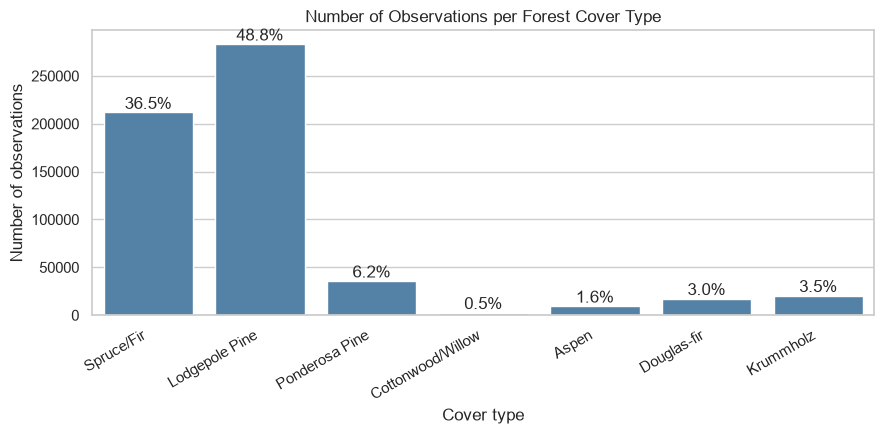

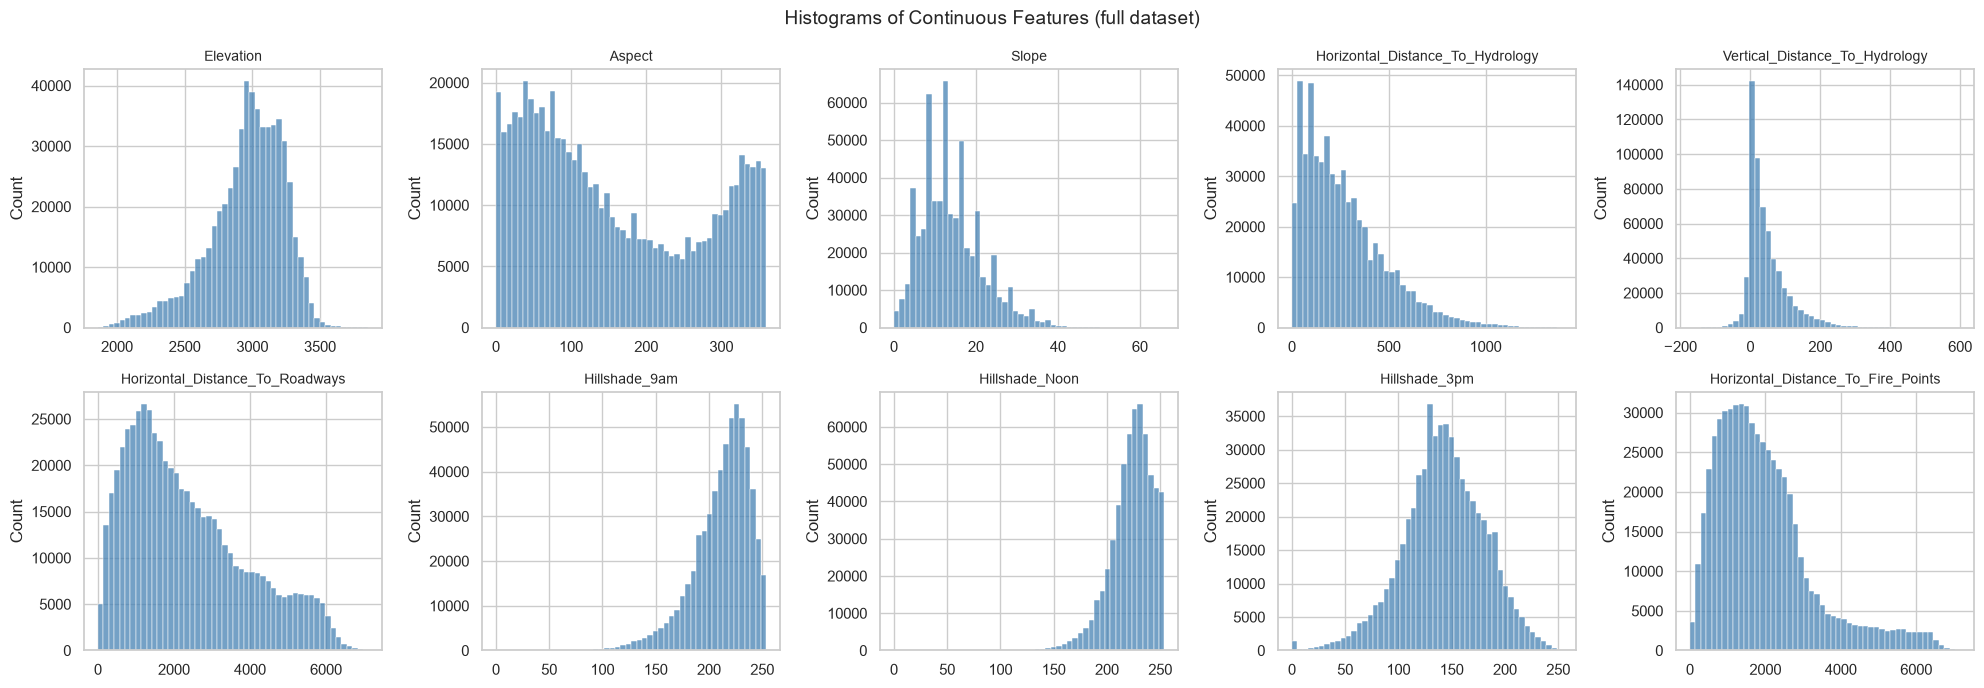

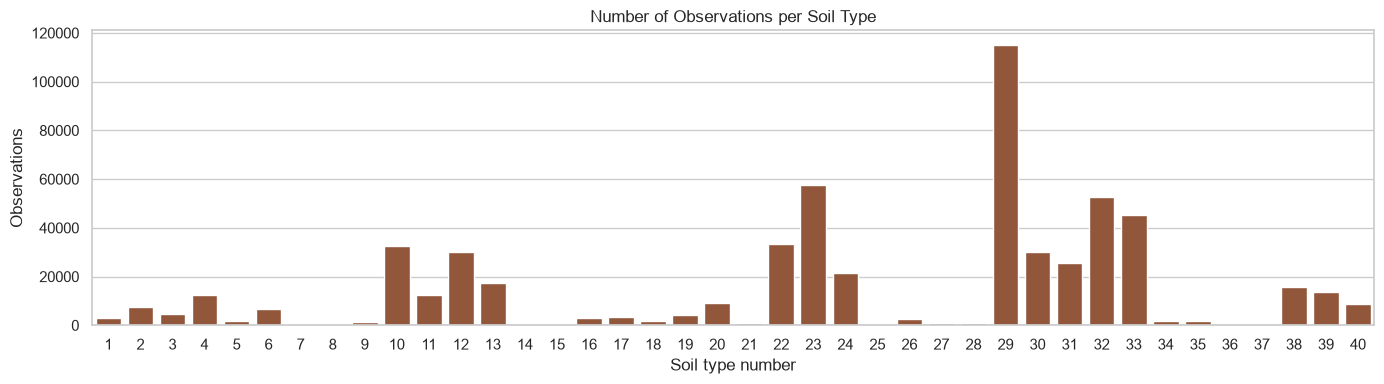

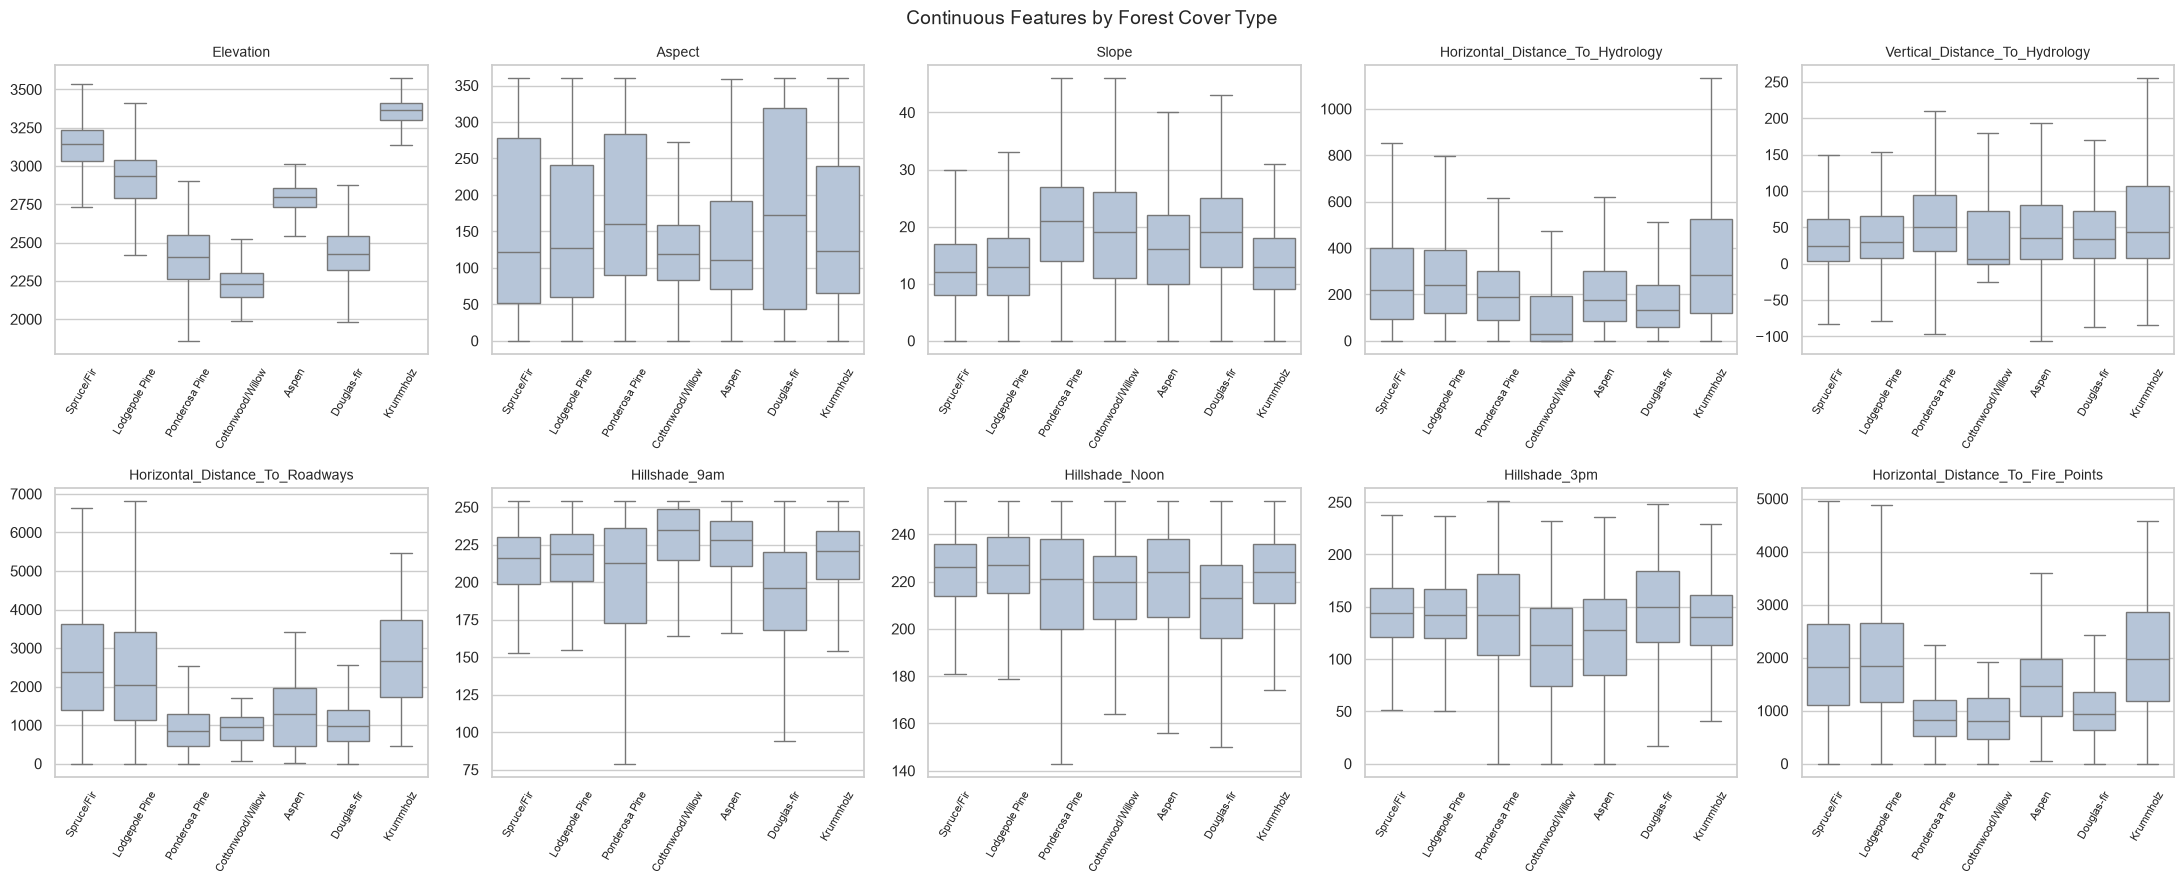

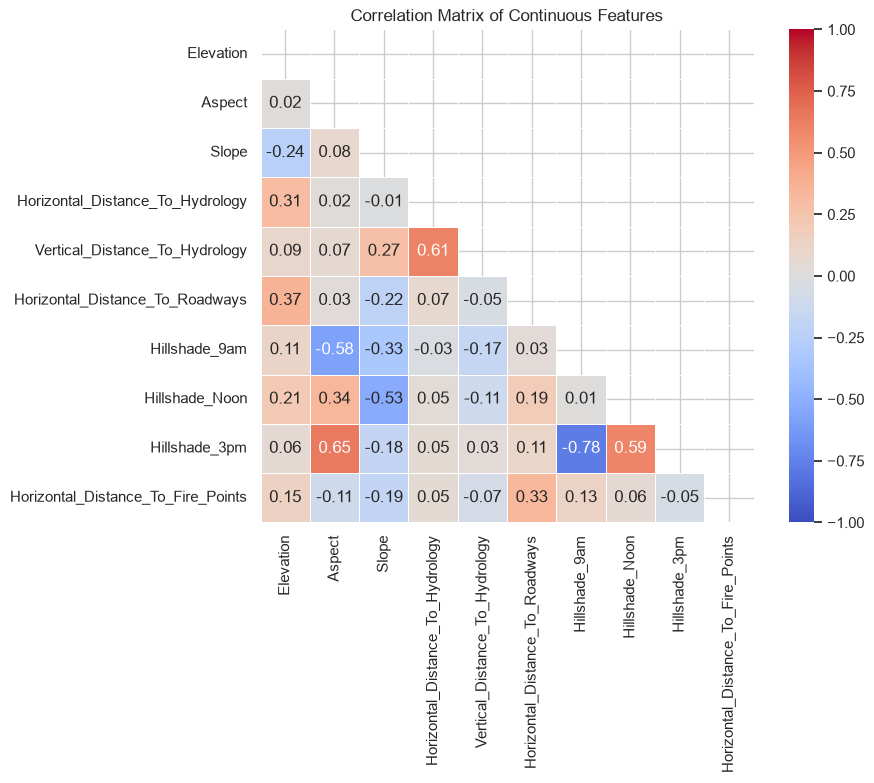

Correlation
Hillshade_3pm                  Hillshade_9am                          -0.780
                               Aspect                                  0.647
Vertical_Distance_To_Hydrology Horizontal_Distance_To_Hydrology        0.606
Hillshade_3pm                  Hillshade_Noon                          0.594
Hillshade_9am                  Aspect                                 -0.579
Hillshade_Noon                 Slope                                  -0.527

In [39]:
# Build a small DataFrame just for the EDA plots
# It wouldn't make sense to plot the one-hot columns directly (44 separate 0/1 columns),
# so this copy of the df uses the original columns and collapses them back into single labeled columns. 
# 
# This copy is only for EDA plotting purposes. The models will still use the one-hot columns

eda_df = df[continuous_cols].copy()

# argmax finds the position of the "1" in each row. Adding 1 converts the 0-based position into the 1-based area/soil number used in covtype.info
wilderness_num = df[wilderness_cols].to_numpy().argmax(axis=1) + 1
soil_num = df[soil_cols].to_numpy().argmax(axis=1) + 1

eda_df["Wilderness"] = pd.Series(wilderness_num, index=df.index).map(wilderness_names)
eda_df["Soil_Type"] = soil_num
eda_df["Cover"] = pd.Categorical(df[target_col].map(cover_type_names), categories=cover_type_order, ordered=True)

# display the first few rows of the EDA DataFrame so the format of each column is visible
# display(eda_df.head())

#---------

# Plot the number of observations in each cover type class to see if the dataset is balanced or imbalanced
class_counts = eda_df["Cover"].value_counts().reindex(cover_type_order)
class_pct = 100 * class_counts / class_counts.sum()
# Bar chart
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=class_counts.index, y=class_counts.values, color="steelblue", ax=ax)
# Label each bar with its percentage so the imbalance is easy to read
for i, pct in enumerate(class_pct):
    ax.text(i, class_counts.iloc[i], f"{pct:.1f}%", ha="center", va="bottom")

ax.set_title("Number of Observations per Forest Cover Type")
ax.set_xlabel("Cover type")
ax.set_ylabel("Number of observations")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#---------

# Plot histograms of the 10 continuous features to see their distributions

fig, axes = plt.subplots(2, 5, figsize=(20, 7))

# axes is a 2x5 grid; flatten() turns it into a simple list of 10 plots
for ax, col in zip(axes.flatten(), continuous_cols):
    sns.histplot(eda_df[col], bins=50, ax=ax, color="steelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

fig.suptitle("Histograms of Continuous Features (full dataset)", fontsize=14)
plt.tight_layout()
plt.show()

# Skew puts a number on what the histograms show
# Generally, skew<.5 is fairly symmetric, skew>1 is strongly skewed
eda_df[continuous_cols].skew().round(2).to_frame("Skewness")

#---------

# Plot how common each soil type is overall (bar chart)
soil_freq = eda_df["Soil_Type"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 4))
sns.barplot(x=soil_freq.index, y=soil_freq.values, color="sienna", ax=ax)
ax.set_title("Number of Observations per Soil Type")
ax.set_xlabel("Soil type number")
ax.set_ylabel("Observations")
plt.tight_layout()
plt.show()

#---------

# Display box plots for each continuous feature broken down by cover type
# Boxes at very different heights for different classes is often indicative of a useful feature for prediction

fig, axes = plt.subplots(2, 5, figsize=(22, 9))

for ax, col in zip(axes.flatten(), continuous_cols):
    # showfliers=False hides the individual outlier dots. There are too many of them and they make the boxes hard to read
    sns.boxplot(data=eda_df, x="Cover", y=col, ax=ax, showfliers=False, color="lightsteelblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=60, labelsize=8)

fig.suptitle("Continuous Features by Forest Cover Type", fontsize=14)
plt.tight_layout()
plt.show()

#---------

# A correlation matrix shows which features carry similar information
# Pearson correlation values near +1 or -1 mean two features move together closely, and values near 0 mean little linear relationship 
# Highly correlated features are not a problem for tree models, but they are worth noting for interpreting feature importance later

corr = eda_df[continuous_cols].corr()

# Only show the lower triangle, since the upper half is a mirror image
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Matrix of Continuous Features")
plt.tight_layout()
plt.show()

# List the most strongly correlated pairs so they are easy to reference in the discussion
# stack() turns the matrix into a list of (feature A, feature B) pairs
pairs = corr.where(~mask).stack().rename("Correlation")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(6).round(3).to_frame()



#### Discussion of EDA plots

Some important observations can be made based on the EDA plots above. First, the target variable itself is unbalanced, with 2 of the 7 cover types accounting for ~85% of all observations. The unbalanced data may make it difficult for the models to correctly predict the 5 less common cover types. Stratified sampling will be critical to preserve the class proportions. 

When examining the 10 continuous features, many of the distance based features exhibit a noticeable skew. Elevation and Hillshade 3pm seem to have the most symmetric distributions. As previously discussed in the summary, the value ranges will need to be addressed when prepping the data for SVM. Soil types are also unevenly distributed, with observations concentrated among about a dozen soil types. 

The box plots of continuous features broken down by cover type are useful for predictive purposes. Boxes at very different heights for different classes is often indicative of a useful feature for prediction, while many overlapping boxes indicates the feature may be less useful. Based on this theory, I can predict that elevation will be found to be the strongest predictor of cover type. Other features show more overlap but may still be useful when considered together with additional environmental variables.

The correlation matrix shows which features carry similar information and are therefore highly correlated. Pearson correlation values near 1 or -1 mean two features move together closely, and values near 0 mean there is little linear relationship. Most features have relatively weak correlations, although there are stronger relationships among some of the hillshade variables and between horizontal and vertical distance to hydrology. Correlated features do not necessarily need to be removed for Decision Tree or Random Forest models, but they should be considered when interpreting feature importance because correlated variables may compete for importance within a model.

---



## IC: Project Design and Special Considerations

To ensure consistency of metrics across models, one evaluation function will be written and then run on every model. The metrics recorded will be as follows:
   - Train and test accuracy: the gap between them is a sign of overfitting
   - Macro precision, recall, and F1: "macro" means the score is computed for each class separately and then averaged, so every cover type counts equally no matter how rare it is. This matters because the classes are imbalanced, but it's still necessary to accurately evaluate the results for each class.
   - Fit and predict time: needed for the scalability comparison

Decision Trees and Random Forests split on one feature at a time, so the units of a feature do not matter to them. SVM is different, since it measures distances between points. In an SVM model, a feature measured in thousands (like distance to roadways) would overpower a feature measured from 0 to 1 (like a soil type indicator). Comparing the ranges shows how large this difference is across features.

Below is a summary of the project design for Sections II-V.

Section II: Preliminary Parameter Exploration
- The purpose of Section II is to demonstrate how important parameters affect model behavior and to select reasonable starting values for later testing.
- A medium-sized stratified sample will be used to perform basic parameter experiments for each model. 
- Decision Tree experiments will focus on parameters that control tree complexity
- Random Forest experiments will examine the number and depth of trees 
- SVM experiments will compare linear and RBF kernels and selected values of C and gamma. 

Section III: Repeated Model Evaluation
- Using the starting parameters selected in Section II, all three models will be evaluated across multiple stratified random samples of the full dataset.
- The same sample will be used for all three models within each iteration so the comparisons are fair. 
- Performance metrics including training accuracy, test accuracy, macro precision, macro recall, macro F1, fit time, and prediction time will be stored for each run. 
- These repeated trials will be used to compare average performance, variability, and evidence of overfitting.

Section IV: Model Refinement and Final Tuning
- Results from the repeated evaluations will be used to identify weaknesses such as overfitting, instability, poor minority-class performance, or unnecessary computational cost. 
- Selected hyperparameters will be adjusted and the models will be reevaluated to determine whether performance improves.

Section V: Final Model Comparison and Discussion
- The final model settings will be applied to the largest practical portion of the dataset, ideally the full dataset if computationally feasible. 
- The models will be compared using overall and per-class performance metrics, confusion matrices, training time, stability, interpretability, and practical strengths and weaknesses. 
- Final discussion will explain which model provides the best overall balance for this dataset and why.

In [43]:
# Define the evaluation function that will be used to fit each model and return a dictionary of performance metrics
def evaluate_model(model, X_train, y_train, X_test, y_test):
    """Fit a model, then return a dictionary of performance metrics."""

    # Time the training step
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    # Time the prediction step on the test set
    start = time.perf_counter()
    y_test_pred = model.predict(X_test)
    predict_time = time.perf_counter() - start

    # Predictions on the training data are only used to measure overfitting
    y_train_pred = model.predict(X_train)

    # zero_division=0 avoids a warning if a model never predicts some class
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_test_pred, average="macro", zero_division=0
    )

    return {
        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Fit Time (s)": fit_time,
        "Predict Time (s)": predict_time,
    }


---

## Section II: Preliminary Models and Hyperparameter Observations

This section will create a medium-sized stratified random sample on which each of the 3 models can be trained. The three models used are Decision Tree, Random Forest, and SVM. 
- Decision Tree will serve as the "baseline" model. It's easy to interpret, no scaling needed, and handles the mix of continuous and 0/1 columns.
- Random Forest should be an improvement over decision tree, since it averages many trees built on bootstrap samples and random feature subsets. This is done to reduce the variance (overfitting) of a single tree
- SVM will be the final model used. SVM is margin based instead of rule based. Linear and RBF kernels will be run. RBF can draw nonlinear boundaries, but it needs scaled features and is expected to scale poorly to large samples

Each model will be trained on a set of hyperparameters that should illustrate how the hyperparameters affect the model performance. This section's exploration of hyperparameters of each model will determine the starting values for final model parameters.

First, one random stratified sample will be drawn from the dataset. All models will use this identical sample to ensure fairness in comparing metrics. Using the same sample for all three models ensures that any difference in metrics is a result of the model and its parameters. 20000 was chosen as the best sample size for this section, split into a 15000 observation training set and a 5000 observation testing set.

5-fold stratified cross-validation is used for every grid search in this section, which is data science best practice.

In [44]:
# Set sample size for the development set that will be used for all models in this section
dev_sample_size = 20_000

# use the function defined in section I to draw a stratified sample of the requested size from the full dataset
dev_sample = get_stratified_sample(df, dev_sample_size)
X_train, X_test, y_train, y_test = split_features_target(dev_sample)   # 75% train / 25% test, both stratified
# verify that the training and test sets have the expected number of rows
print(f"Training rows: {len(X_train):,}   Test rows: {len(X_test):,}")

# use k-fold stratified cross-validation for every grid search in this section
# shuffle=True mixes the rows before they are split into folds, and stratifying keeps every fold at the same class proportions as the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Macro F1 is used to pick the best settings instead of accuracy
# Accuracy can look good just by predicting the two big classes well, while macro F1 counts every cover type equally
cv_scoring = "f1_macro"

# Test set metrics for the baselines and the tuned models are stored here (model name -> metrics dictionary)
# A dictionary is used instead of a list so that re-running a cell replaces its row instead of adding a duplicate
summary_results = {}

# Run sweep function trains one model per value of a single hyperparameter and collects the metrics in a DataFrame.
def run_sweep(build_model, param_name, values):
    """Train one model per value of a single hyperparameter and collect the metrics in a DataFrame.

    build_model is a function that takes one hyperparameter value and returns a new, unfitted model.
    Every model is trained on X_train and scored on X_test using evaluate_model() from Section I.
    """
    rows = []
    for value in values:
        model = build_model(value)
        metrics = evaluate_model(model, X_train, y_train, X_test, y_test)
        metrics[param_name] = value
        rows.append(metrics)

    # Move the hyperparameter column to the front so the table is easier to read
    sweep_df = pd.DataFrame(rows)
    # pandas would turn None into NaN (and 2 into 2.0), so the original values are put back as plain Python objects
    sweep_df[param_name] = pd.Series(values, dtype=object)
    return sweep_df[[param_name] + [c for c in sweep_df.columns if c != param_name]]

# Plotting function for hyperparameter sweeps
def plot_sweep(sweep_df, param_name, title):
    """Plot train vs. test accuracy, test macro F1, and fit time for one hyperparameter sweep."""
    # Values like None can't be placed on a numeric axis, so the values are evenly spaced and labeled as text instead
    # This also works well for values that grow by factors of 10, like C for the SVM
    x = np.arange(len(sweep_df))
    labels = sweep_df[param_name].map(str)

    fig, (ax_score, ax_time) = plt.subplots(1, 2, figsize=(13, 4.5))

    # Left plot: a large gap between the train and test lines is a sign of overfitting
    ax_score.plot(x, sweep_df["Train Accuracy"], marker="o", label="Train accuracy")
    ax_score.plot(x, sweep_df["Test Accuracy"], marker="o", label="Test accuracy")
    ax_score.plot(x, sweep_df["Macro F1"], marker="s", linestyle="--", label="Test macro F1")
    ax_score.set_xticks(x, labels)
    ax_score.set_xlabel(param_name)
    ax_score.set_ylabel("Score")
    ax_score.set_title("Scores")
    ax_score.legend()

    # Right plot: how much longer training takes as the setting changes
    ax_time.plot(x, sweep_df["Fit Time (s)"], marker="o", color="gray")
    ax_time.set_xticks(x, labels)
    ax_time.set_xlabel(param_name)
    ax_time.set_ylabel("Seconds")
    ax_time.set_title("Fit time")

    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

# Function to display the best hyperparameter combinations from a GridSearchCV as a small table
def show_top_cv_results(grid, n=5):
    """Return the n best hyperparameter combinations from a fitted GridSearchCV as a small table."""
    results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score").head(n)

    # The params column holds dictionaries, which print in a cluttered way, so they are turned into short "name=value" text
    # The "svc__" prefix (from the SVM pipeline) is removed so the names are easier to read
    params_text = results["params"].apply(
        lambda p: ", ".join(f"{k.replace('svc__', '')}={v}" for k, v in p.items())
    )
    return pd.DataFrame({
        "Parameters": params_text.values,
        "Mean CV Macro F1": results["mean_test_score"].values,
        "Std CV Macro F1": results["std_test_score"].values,
        "Mean Fit Time (s)": results["mean_fit_time"].values,
    }).round(4)


# Show how many rows of each class ended up in the training set
# The rarest classes are worth watching, because the models have very few examples to learn them from
y_train.map(cover_type_names).value_counts().reindex(cover_type_order).to_frame("Training rows")


Training rows: 15,000   Test rows: 5,000


,Training rows
Cover_Type,
Spruce/Fir,5469
Lodgepole Pine,7314
Ponderosa Pine,923
Cottonwood/Willow,71
Aspen,245
Douglas-fir,449
Krummholz,529


#### Baseline Models

Baseline 1: a "majority class" model that ignores the features and always predicts the most common cover type (Lodgepole Pine). Any real model needs to beat this. Its macro F1 also shows how misleading accuracy alone can be with imbalanced classes

Baseline 2: a Decision Tree with all of sklearn's default settings (no depth limit and no tuning). This is the simplest real model, so the tuned models later in this section are compared against it


In [45]:
# dummy is a simple baseline that always predicts the majority class (cover type 1)
dummy = DummyClassifier(strategy="most_frequent")

# Decision Tree with all of sklearn's default settings (no depth limit and no tuning)
basic_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)

summary_results["Majority Class (Dummy)"] = evaluate_model(dummy, X_train, y_train, X_test, y_test)
summary_results["Basic Decision Tree"] = evaluate_model(basic_tree, X_train, y_train, X_test, y_test)

# With no depth limit the tree keeps splitting until every leaf is pure, so its size gives a hint about overfitting
print(f"Basic tree depth: {basic_tree.get_depth()}   Number of leaves: {basic_tree.get_n_leaves():,}")

pd.DataFrame(summary_results).T.round(4)


Basic tree depth: 33   Number of leaves: 2,341


,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
Majority Class (Dummy),0.4876,0.4876,0.0697,0.1429,0.0937,0.0020,0.0006
Basic Decision Tree,1.0000,0.7718,0.6518,0.6755,0.6629,0.1922,0.0035


#### IIA: Decision Tree (DT)
DT1
- max_depth limits how many levels of splits the tree is allowed to make
- shallow trees are simple but may underfit, and a tree with no limit (None) keeps splitting until its leaves are pure, which usually overfits

DT2
- min_samples_leaf is the smallest number of training rows allowed in a leaf
- Raising min_samples_leaf stops the tree from making leaves for just one or two unusual rows, which is another way to limit overfitting
- max_depth is left at None here so the effect of this setting can be seen on its own

DT Grid Search
- GridSearchCV tries every combination of the two settings and scores each one with 5-fold cross-validation on the training set only
- The test set is not used to choose the settings... it is only used afterwards to check the chosen model
- n_jobs=-1 runs the folds in parallel on all CPU cores to save time

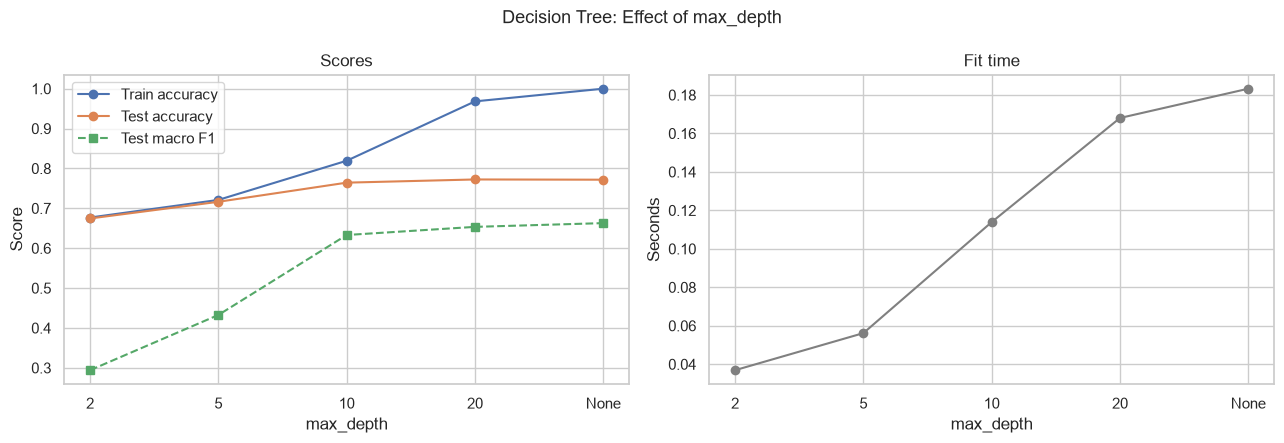

,max_depth,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
0,2,0.6769,0.6746,0.2768,0.3148,0.2942,0.0369,0.0047
1,5,0.7211,0.7164,0.5676,0.4279,0.4326,0.0562,0.0023
2,10,0.8193,0.7644,0.7162,0.5949,0.6331,0.1139,0.0027
3,20,0.9682,0.7724,0.6520,0.6567,0.6535,0.1680,0.0028
4,None,1.0000,0.7718,0.6518,0.6755,0.6629,0.1833,0.0028


In [46]:
# Decision Tree sweep 1: max_depth

# vary max_depth to see how it affects overfitting and underfitting
dt_depth_values = [2, 5, 10, 20, None]

dt_depth_sweep = run_sweep(
    lambda d: DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
    "max_depth",
    dt_depth_values,
)

plot_sweep(dt_depth_sweep, "max_depth", "Decision Tree: Effect of max_depth")
dt_depth_sweep.round(4)


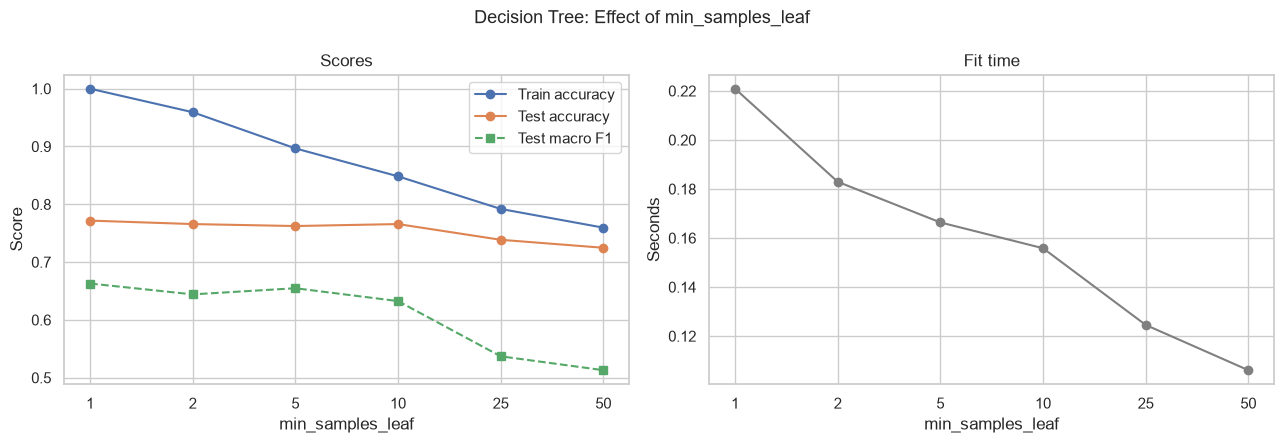

,min_samples_leaf,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
0,1,1.0000,0.7718,0.6518,0.6755,0.6629,0.2209,0.0035
1,2,0.9593,0.7658,0.6709,0.6270,0.6442,0.1829,0.0029
2,5,0.8967,0.7624,0.6744,0.6399,0.6548,0.1663,0.0027
3,10,0.8484,0.7658,0.6565,0.6167,0.6326,0.1558,0.0027
4,25,0.7920,0.7386,0.6119,0.5087,0.5371,0.1245,0.0026
5,50,0.7596,0.7248,0.5659,0.5033,0.5130,0.1061,0.0025


In [47]:
# Decision Tree sweep 2: min_samples_leaf
# vary min_samples_leaf to see how it affects overfitting and underfitting
dt_leaf_values = [1, 2, 5, 10, 25, 50]

dt_leaf_sweep = run_sweep(
    lambda n: DecisionTreeClassifier(min_samples_leaf=n, random_state=RANDOM_STATE),
    "min_samples_leaf",
    dt_leaf_values,
)

plot_sweep(dt_leaf_sweep, "min_samples_leaf", "Decision Tree: Effect of min_samples_leaf")
dt_leaf_sweep.round(4)


In [49]:
# Decision Tree grid search

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={
        "max_depth": [5, 10, 15, 20, None],
        "min_samples_leaf": [1, 2, 5, 10],
    },
    scoring=cv_scoring,
    cv=cv,
    n_jobs=-1,
)
dt_grid.fit(X_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print(f"Best mean CV macro F1: {dt_grid.best_score_:.4f}")
display(show_top_cv_results(dt_grid))

# Score the best combination on the test set with the same evaluation function as every other model
summary_results["Tuned Decision Tree"] = evaluate_model(dt_grid.best_estimator_, X_train, y_train, X_test, y_test)
pd.Series(summary_results["Tuned Decision Tree"]).round(4).to_frame("Tuned DT (test set)")


Best parameters: {'max_depth': None, 'min_samples_leaf': 2}
Best mean CV macro F1: 0.6226


,Parameters,Mean CV Macro F1,Std CV Macro F1,Mean Fit Time (s)
0,"max_depth=None, min_samples_leaf=2",0.6226,0.0393,0.2993
1,"max_depth=None, min_samples_leaf=1",0.6193,0.0198,0.3078
2,"max_depth=20, min_samples_leaf=2",0.6182,0.0387,0.3559
3,"max_depth=20, min_samples_leaf=1",0.6113,0.0202,0.3489
4,"max_depth=15, min_samples_leaf=1",0.6087,0.0244,0.2620


,Tuned DT (test set)
Train Accuracy,0.9593
Test Accuracy,0.7658
Macro Precision,0.6709
Macro Recall,0.6270
Macro F1,0.6442
Fit Time (s),0.1825
Predict Time (s),0.0030


#### Decision Tree Discussion

Based on the above results, the parameters selected for the final model training will be ... because ...

#### II B: Random Forest (RF)

RF1
- n_estimators is the number of trees in the forest
- Each tree is trained on a bootstrap sample of the rows and only looks at a random subset of features at each split
- The forest predicts by majority vote, so more trees should make predictions more stable, but training time should grow roughly linearly with the number of trees

RF2
- Unlike a single tree, a forest of fully grown trees often does not overfit as badly, because averaging many different trees cancels out some of their individual mistakes
- This sweep checks whether limiting depth still helps. n_estimators is held at 100 so only max_depth changes

RF Grid Search
- GridSearchCV tries every combination of the two settings and scores each one with 5-fold cross-validation on the training set only

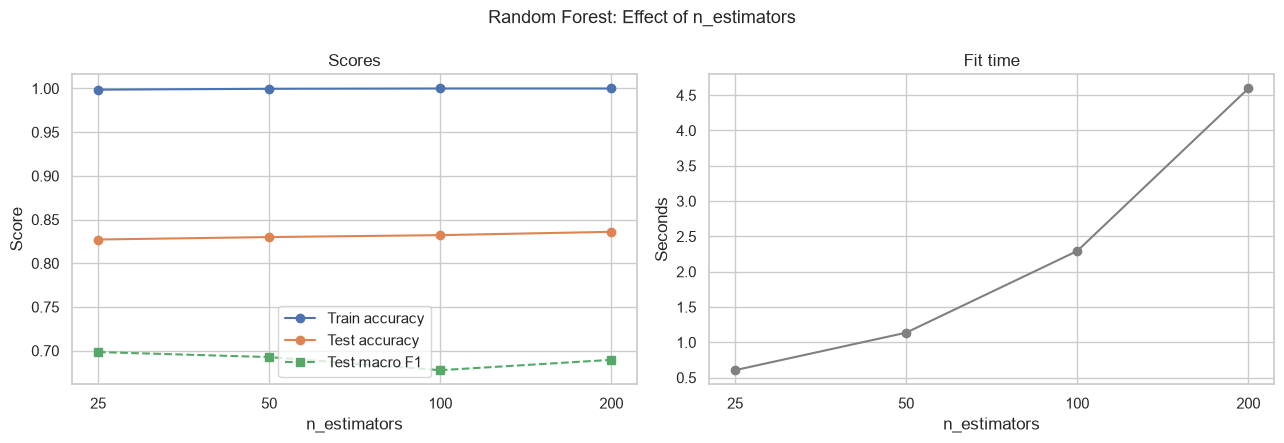

,n_estimators,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
0,25,0.9987,0.8272,0.8206,0.6484,0.6984,0.6054,0.0237
1,50,0.9997,0.8300,0.8300,0.6413,0.6927,1.1366,0.0444
2,100,1.0000,0.8322,0.8006,0.6318,0.6777,2.2934,0.0894
3,200,1.0000,0.8360,0.8238,0.6408,0.6895,4.5947,0.1742


In [50]:
# Random Forest sweep 1: n_estimators
# define a list of values to try for the number of trees in the forest
rf_tree_values = [25, 50, 100, 200]

rf_trees_sweep = run_sweep(
    lambda n: RandomForestClassifier(n_estimators=n, random_state=RANDOM_STATE),
    "n_estimators",
    rf_tree_values,
)

plot_sweep(rf_trees_sweep, "n_estimators", "Random Forest: Effect of n_estimators")
rf_trees_sweep.round(4)


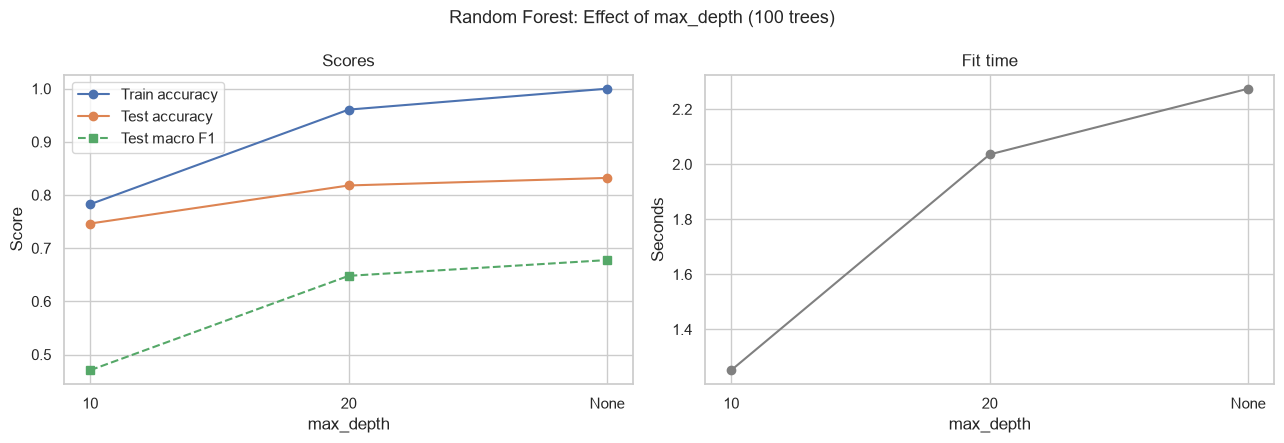

,max_depth,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
0,10,0.7827,0.7464,0.8397,0.4435,0.4706,1.2517,0.0423
1,20,0.9607,0.8180,0.8274,0.5995,0.6480,2.0357,0.0792
2,None,1.0000,0.8322,0.8006,0.6318,0.6777,2.2746,0.0927


In [51]:
# Random Forest sweep 2: max_depth
# define a list of values to try for the maximum depth of each tree in the forest
rf_depth_values = [10, 20, None]

rf_depth_sweep = run_sweep(
    lambda d: RandomForestClassifier(n_estimators=100, max_depth=d, random_state=RANDOM_STATE),
    "max_depth",
    rf_depth_values,
)

plot_sweep(rf_depth_sweep, "max_depth", "Random Forest: Effect of max_depth (100 trees)")
rf_depth_sweep.round(4)


In [53]:
# Random Forest grid search over both settings (4 x 3 = 12 combinations, 60 fits with 5 folds)
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid={
        "n_estimators": rf_tree_values,
        "max_depth": rf_depth_values,
    },
    scoring=cv_scoring,
    cv=cv,
    n_jobs=-1,
)
rf_grid.fit(X_train, y_train)

print("Best parameters:", rf_grid.best_params_)
print(f"Best mean CV macro F1: {rf_grid.best_score_:.4f}")
display(show_top_cv_results(rf_grid))

summary_results["Tuned Random Forest"] = evaluate_model(rf_grid.best_estimator_, X_train, y_train, X_test, y_test)
pd.Series(summary_results["Tuned Random Forest"]).round(4).to_frame("Tuned RF (test set)")


Best parameters: {'max_depth': None, 'n_estimators': 200}
Best mean CV macro F1: 0.6900


,Parameters,Mean CV Macro F1,Std CV Macro F1,Mean Fit Time (s)
0,"max_depth=None, n_estimators=200",0.6900,0.0285,5.6212
1,"max_depth=None, n_estimators=100",0.6882,0.0264,3.7450
2,"max_depth=None, n_estimators=50",0.6853,0.0335,1.9104
3,"max_depth=None, n_estimators=25",0.6830,0.0294,0.9705
4,"max_depth=20, n_estimators=200",0.6745,0.0312,6.7439


,Tuned RF (test set)
Train Accuracy,1.0000
Test Accuracy,0.8360
Macro Precision,0.8238
Macro Recall,0.6408
Macro F1,0.6895
Fit Time (s),4.6827
Predict Time (s),0.1735


#### II C: Support Vector Machine (SVM)

SVM 1: C varies, gamma constant, and using both linear and RBF kernels
- The SVM is always built as a pipeline: StandardScaler first, then SVC
- The scaler rescales every feature to mean 0 and standard deviation 1 (see Section I C for why SVM needs this)
- Keeping the scaler inside the pipeline means it is fit only on the training rows, including inside each cross-validation fold, so no information from the test rows leaks into training
- C controls how much the SVM is penalized for misclassifying training points
- A small C allows more mistakes and gives a smoother, simpler boundary, while a large C tries to classify every training point correctly and can overfit
- Linear kernel: a short C sweep for comparison only
- The linear kernel can only draw straight boundaries between classes, so it is a reference point for checking whether the curved boundaries of the RBF kernel are actually needed
- The linear kernel is not tuned any further after this sweep
- The RBF kernel can draw curved boundaries, so it is the kernel that gets tuned further in the grid search

SVM 2: Grid Search varying C and gamma and using RBF kernel only
- gamma controls how far the influence of a single training point reaches
- A small gamma lets each point influence a wide area (smoother boundary), while a large gamma means each point only affects its close neighbors (a very wiggly boundary that can overfit)
- "scale" is sklearn's default, which is 1 / (number of features * variance of X). After standardizing, the variance is 1, so "scale" works out to about 1/54 = 0.019
- C = 0.1 was left out of the grid because the sweep above already showed it scoring far below the larger values

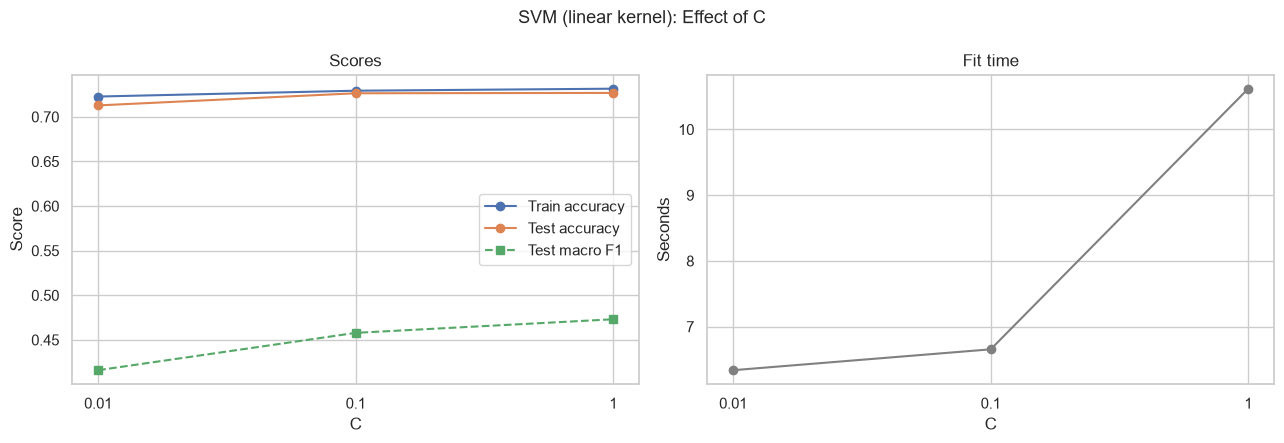

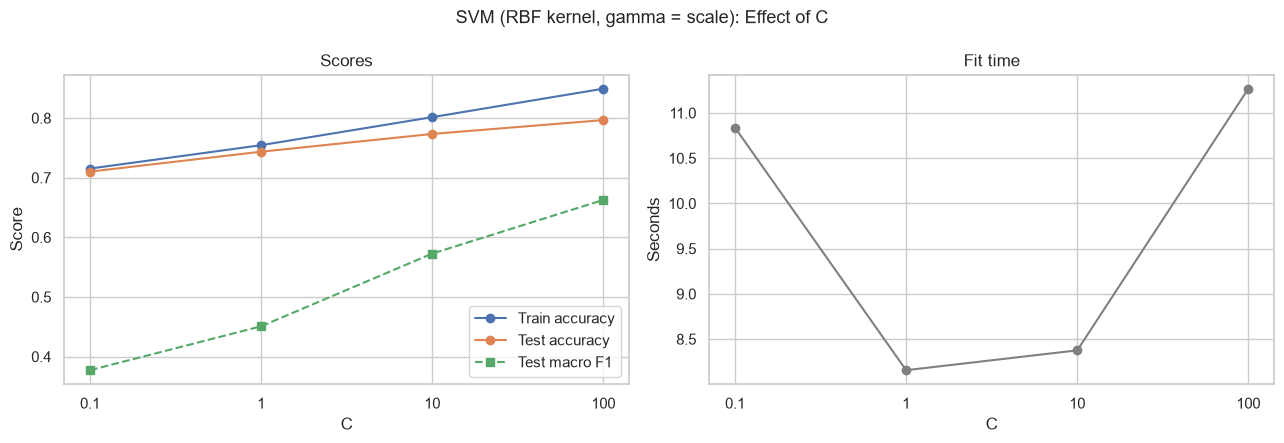

,kernel,C,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
0,linear,0.01,0.7227,0.7128,0.5052,0.4396,0.4160,6.3377,1.5419
1,linear,0.1,0.7293,0.7264,0.5139,0.4630,0.4579,6.6551,1.4215
2,linear,1,0.7315,0.7268,0.5608,0.4716,0.4731,10.6196,1.5227
3,rbf,0.1,0.7153,0.7102,0.3897,0.3914,0.3772,10.8371,5.3368
4,rbf,1,0.7545,0.7436,0.5532,0.4549,0.4508,8.1563,4.6200
5,rbf,10,0.8015,0.7734,0.7094,0.5450,0.5728,8.3756,4.1548
6,rbf,100,0.8493,0.7966,0.7439,0.6333,0.6627,11.2683,3.8063


In [55]:
# SVM sweep 1: C varies, and both linear and RBF kernels are tested.
def build_svm(kernel, C, gamma="scale", class_weight=None):
    """Return an unfitted StandardScaler + SVC pipeline."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel=kernel, C=C, gamma=gamma, class_weight=class_weight)),
    ])

# Linear kernel: C sweep
# initially attempted to sweep over C=10 and C=100, but the linear kernel SVM took too long to train on 20k rows, so the sweep was limited to smaller values
linear_C_values = [0.01, 0.1, 1]
svm_linear_sweep = run_sweep(lambda C: build_svm("linear", C), "C", linear_C_values)
plot_sweep(svm_linear_sweep, "C", "SVM (linear kernel): Effect of C")

# RBF kernel: C sweep with gamma held at its default value ("scale"). RBF kernel was efficient enough to allow a wider range of C values to be tested
rbf_C_values = [0.1, 1, 10, 100]
svm_rbf_sweep = run_sweep(lambda C: build_svm("rbf", C), "C", rbf_C_values)
plot_sweep(svm_rbf_sweep, "C", "SVM (RBF kernel, gamma = scale): Effect of C")

# Label the rows with their kernel so both sweeps can share one table
svm_linear_sweep.insert(0, "kernel", "linear")
svm_rbf_sweep.insert(0, "kernel", "rbf")
svm_sweep = pd.concat([svm_linear_sweep, svm_rbf_sweep], ignore_index=True)
svm_sweep.round(4)


Best parameters: {'svc__C': 100, 'svc__gamma': 0.1}
Best mean CV macro F1: 0.6871


,Parameters,Mean CV Macro F1,Std CV Macro F1,Mean Fit Time (s)
0,"C=100, gamma=0.1",0.6871,0.0098,33.0124
1,"C=10, gamma=0.1",0.6682,0.0235,30.7486
2,"C=100, gamma=scale",0.6638,0.0237,26.7839
3,"C=10, gamma=1",0.6131,0.0155,138.7099
4,"C=100, gamma=1",0.6126,0.0159,76.3060
5,"C=10, gamma=scale",0.5885,0.0191,24.6467
6,"C=1, gamma=0.1",0.5647,0.0195,32.4373
7,"C=1, gamma=1",0.5319,0.0338,135.6596
8,"C=1, gamma=scale",0.4810,0.0193,27.6242


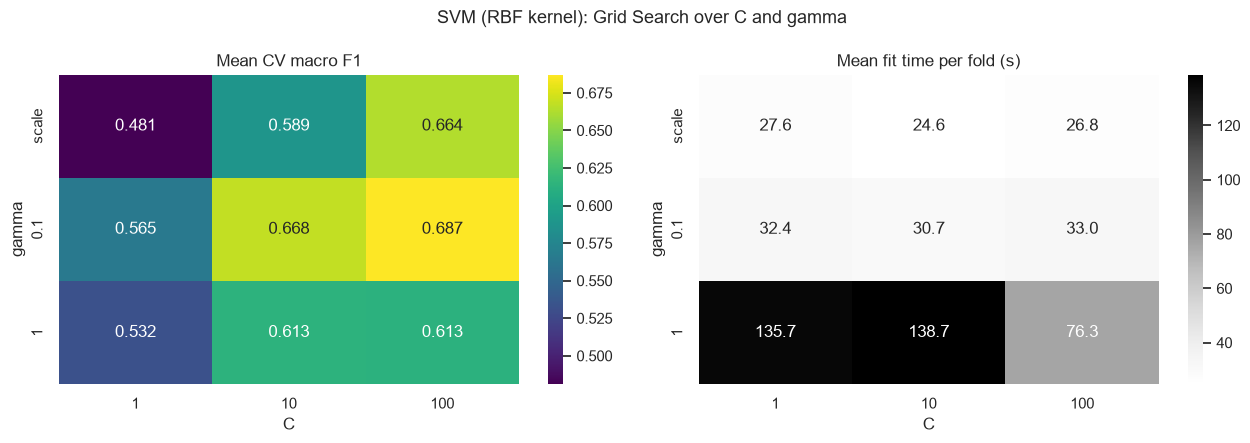

,Tuned SVM (test set)
Train Accuracy,0.9420
Test Accuracy,0.8158
Macro Precision,0.7168
Macro Recall,0.6774
Macro F1,0.6937
Fit Time (s),15.5410
Predict Time (s),3.6014


In [56]:
# SVM grid search: C and gamma for the RBF kernel (3 x 3 = 9 combinations, 45 fits with 5 folds)
# Inside a pipeline, each setting is named "<step name>__<parameter>", so C for the SVC step is written as "svc__C"
svm_grid_C_values = [1, 10, 100]            # C values limited due to long training times for larger values. The RBF kernel is more sensitive to C than the linear kernel, so the range of values is shifted up.
svm_gamma_values = ["scale", 0.1, 1]        # "scale" is the default value, and 0.1 and 1 are chosen to be roughly one order of magnitude smaller and larger than the default

svm_grid = GridSearchCV(
    build_svm("rbf", 1),   # the starting C doesn't matter, the grid replaces it
    param_grid={
        "svc__C": svm_grid_C_values,
        "svc__gamma": svm_gamma_values,
    },
    scoring=cv_scoring,
    cv=cv,
    n_jobs=-1,
)
svm_grid.fit(X_train, y_train)

print("Best parameters:", svm_grid.best_params_)
print(f"Best mean CV macro F1: {svm_grid.best_score_:.4f}")
display(show_top_cv_results(svm_grid, n=9))

# Heatmaps of the grid results: mean CV macro F1 and mean fit time for every C and gamma combination
# The C and gamma values are turned into text so "scale" and the numbers can share one axis
svm_cv_table = pd.DataFrame(svm_grid.cv_results_)
svm_cv_table["C"] = svm_cv_table["param_svc__C"].map(str)
svm_cv_table["gamma"] = svm_cv_table["param_svc__gamma"].map(str)
gamma_order = [str(g) for g in svm_gamma_values]
C_order = [str(c) for c in svm_grid_C_values]

fig, (ax_f1, ax_time) = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, value_col, title, fmt, cmap in [
    (ax_f1, "mean_test_score", "Mean CV macro F1", ".3f", "viridis"),
    (ax_time, "mean_fit_time", "Mean fit time per fold (s)", ".1f", "Greys"),
]:
    table = svm_cv_table.pivot(index="gamma", columns="C", values=value_col).reindex(index=gamma_order, columns=C_order)
    sns.heatmap(table, annot=True, fmt=fmt, cmap=cmap, ax=ax)
    ax.set_title(title)
fig.suptitle("SVM (RBF kernel): Grid Search over C and gamma", fontsize=13)
plt.tight_layout()
plt.show()

summary_results["Tuned SVM"] = evaluate_model(svm_grid.best_estimator_, X_train, y_train, X_test, y_test)
pd.Series(summary_results["Tuned SVM"]).round(4).to_frame("Tuned SVM (test set)")


#### Class Weighting: Default vs. Balanced


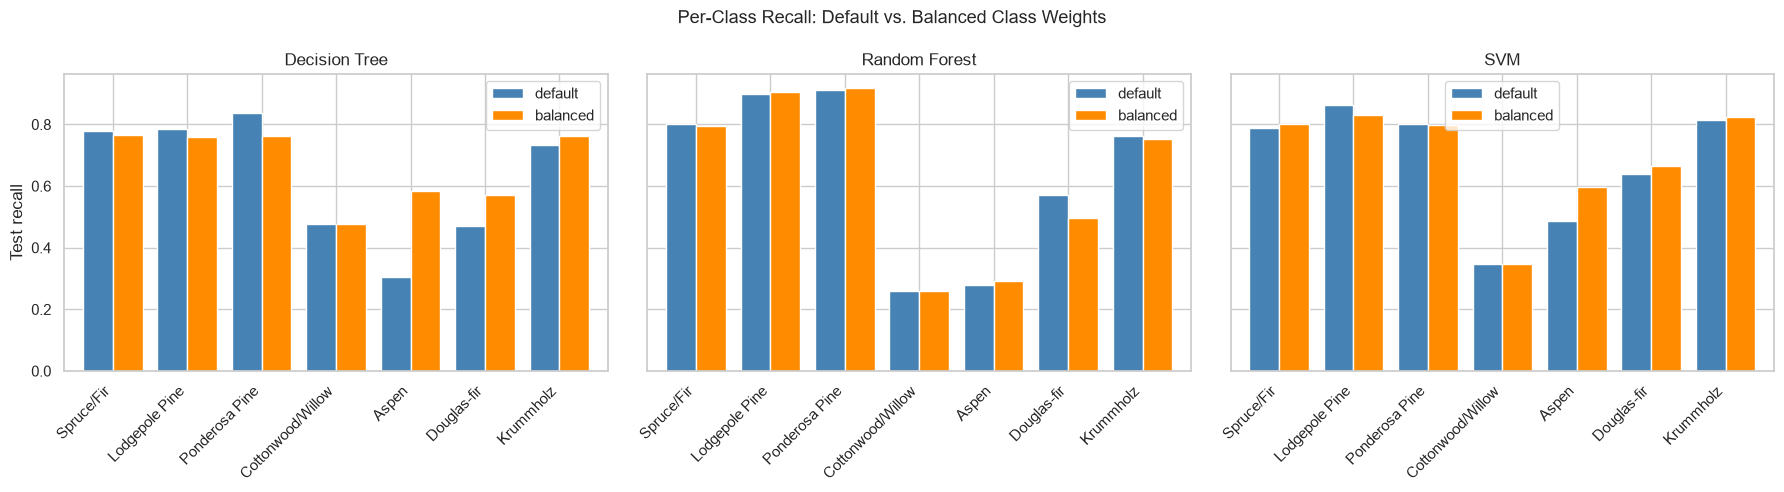

class_weight setting kept for each model (higher CV macro F1): {'Decision Tree': 'balanced', 'Random Forest': None, 'SVM': None}


Mean CV Macro F1  Std CV Macro F1  Train Accuracy  \
Model         class_weight                                                      
Decision Tree default                 0.6226           0.0393          0.9593   
              balanced                0.6257           0.0292          0.9537   
Random Forest default                 0.6900           0.0285          1.0000   
              balanced                0.6826           0.0286          1.0000   
SVM           default                 0.6871           0.0098          0.9420   
              balanced                0.6804           0.0140          0.9205   

                            Test Accuracy  Macro Precision  Macro Recall  \
Model         class_weight                                                 
Decision Tree default              0.7658           0.6709        0.6270   
              balanced             0.7516           0.6184        0.6691   
Random Forest default              0.8360           0.8238        0.6408   
              balanced             0.8356           0.8094        0.6316   
SVM           default              0.8158           0.7168        0.6774   
              balanced             0.8068           0.6799        0.6951   

                            Macro F1  Fit Time (s)  Predict Time (s)  
Model         class_weight                                            
Decision Tree default         0.6442        0.1737            0.0029  
              balanced        0.6415        0.1769            0.0031  
Random Forest default         0.6895        4.5726            0.1753  
              balanced        0.6796        4.4766            0.1850  
SVM           default         0.6937       15.7550            3.6221  
              balanced        0.6868       12.1083            3.8457

In [58]:
# Class weighting comparison
# By default every training row counts the same, so the models are mostly rewarded for getting the two large classes right
# class_weight="balanced" gives each class a weight of n_samples / (n_classes * class_count), so mistakes on rare classes cost more
# For example, Cottonwood/Willow makes up about 0.5% of the rows, so each of its rows counts roughly 30 times as much as an average row
# The expected tradeoff is better recall on the rare cover types in exchange for a little overall accuracy on the large classes
# Each model keeps the settings chosen by its grid search above, so class_weight is the only thing that changes

# Functions that rebuild each tuned model with a given class_weight setting
weighting_builders = {
    "Decision Tree": lambda cw: DecisionTreeClassifier(**dt_grid.best_params_, class_weight=cw, random_state=RANDOM_STATE),
    "Random Forest": lambda cw: RandomForestClassifier(**rf_grid.best_params_, class_weight=cw, random_state=RANDOM_STATE),
    "SVM": lambda cw: build_svm("rbf", svm_grid.best_params_["svc__C"], svm_grid.best_params_["svc__gamma"], class_weight=cw),
}
# In the SVM pipeline the setting belongs to the "svc" step, so its grid name has the "svc__" prefix
weight_param_names = {"Decision Tree": "class_weight", "Random Forest": "class_weight", "SVM": "svc__class_weight"}

class_labels = list(cover_type_names.keys())   # the numeric labels 1-7, in order
cw_settings = [None, "balanced"]

cw_rows = []                 # one row per model per weighting setting
recall_tables = {}           # per-class recall for each model, used for the plot below
class_weight_choice = {}     # the setting with the higher CV macro F1, carried forward to Section III

for name, build in weighting_builders.items():
    # Part 1: cross-validated comparison on the training set, using the same 5 folds as the tuning above
    param = weight_param_names[name]
    cw_grid = GridSearchCV(build(None), {param: cw_settings}, scoring=cv_scoring, cv=cv, n_jobs=-1)
    cw_grid.fit(X_train, y_train)
    cv_res = pd.DataFrame(cw_grid.cv_results_)   # rows come back in the same order as cw_settings
    class_weight_choice[name] = cw_grid.best_params_[param]

    # Part 2: fit each version on the full training set and score it on the test set
    recalls = {}
    for i, cw in enumerate(cw_settings):
        label = "default" if cw is None else "balanced"
        model = build(cw)
        metrics = evaluate_model(model, X_train, y_train, X_test, y_test)

        # average=None returns one recall value per class instead of a single average, which shows exactly which cover types gain or lose from the weighting
        _, class_recall, _, _ = precision_recall_fscore_support(y_test, model.predict(X_test), labels=class_labels, average=None, zero_division=0)
        recalls[label] = class_recall

        cw_rows.append({
            "Model": name,
            "class_weight": label,
            "Mean CV Macro F1": cv_res.loc[i, "mean_test_score"],
            "Std CV Macro F1": cv_res.loc[i, "std_test_score"],
            **metrics,
        })

    recall_tables[name] = pd.DataFrame(recalls, index=cover_type_order)

# Plot per-class test recall, default vs. balanced, for each model
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (name, table) in zip(axes, recall_tables.items()):
    table.plot.bar(ax=ax, color=["steelblue", "darkorange"], width=0.8)
    ax.set_title(name)
    ax.set_xlabel("")
    ax.set_ylabel("Test recall")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
fig.suptitle("Per-Class Recall: Default vs. Balanced Class Weights", fontsize=13)
plt.tight_layout()
plt.show()

print("class_weight setting kept for each model (higher CV macro F1):", class_weight_choice)
cw_results = pd.DataFrame(cw_rows).set_index(["Model", "class_weight"])
cw_results.round(4)


#### Section II Summary


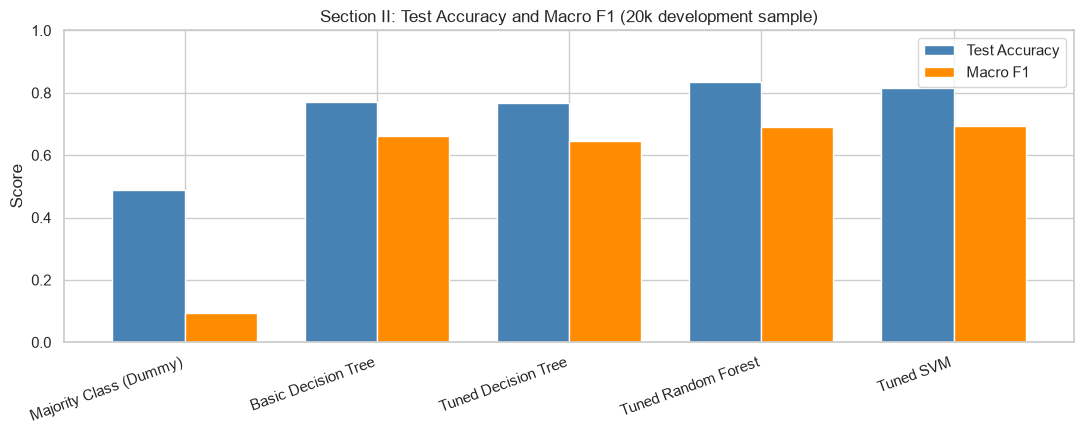

Decision Tree: {'max_depth': None, 'min_samples_leaf': 2, 'class_weight': 'balanced'}
Random Forest: {'max_depth': None, 'n_estimators': 200, 'class_weight': None}
SVM: {'kernel': 'rbf', 'C': 100, 'gamma': 0.1, 'class_weight': None}


,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Fit Time (s),Predict Time (s)
Majority Class (Dummy),0.4876,0.4876,0.0697,0.1429,0.0937,0.0020,0.0006
Basic Decision Tree,1.0000,0.7718,0.6518,0.6755,0.6629,0.1922,0.0035
Tuned Decision Tree,0.9593,0.7658,0.6709,0.6270,0.6442,0.1825,0.0030
Tuned Random Forest,1.0000,0.8360,0.8238,0.6408,0.6895,4.6827,0.1735
Tuned SVM,0.9420,0.8158,0.7168,0.6774,0.6937,15.5410,3.6014


In [59]:
# Combine the baselines and the tuned models into one table of test set results
section2_summary = pd.DataFrame(summary_results).T

# Side by side bar chart of test accuracy and test macro F1 for every model
fig, ax = plt.subplots(figsize=(11, 4.5))
section2_summary[["Test Accuracy", "Macro F1"]].plot.bar(ax=ax, color=["steelblue", "darkorange"], width=0.75)
ax.set_title("Section II: Test Accuracy and Macro F1 (20k development sample)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()

# Save the chosen settings for each model so Section III can build its models from this dictionary
# instead of copying numbers by hand. The SVM names drop the "svc__" prefix because Section III passes them straight to build_svm()
best_params = {
    "Decision Tree": {**dt_grid.best_params_, "class_weight": class_weight_choice["Decision Tree"]},
    "Random Forest": {**rf_grid.best_params_, "class_weight": class_weight_choice["Random Forest"]},
    "SVM": {
        "kernel": "rbf",
        "C": svm_grid.best_params_["svc__C"],
        "gamma": svm_grid.best_params_["svc__gamma"],
        "class_weight": class_weight_choice["SVM"],
    },
}
for name, params in best_params.items():
    print(f"{name}: {params}")

section2_summary.round(4)


Section II Results Discussion

(Placeholder hints for the Section II discussion)
- Baselines: how far above the majority-class model each tuned model landed, and the gap between its accuracy and macro F1
- DT: where the train and test curves split apart (overfitting point), and whether min_samples_leaf or max_depth helped more
- RF: where adding more trees stopped helping, the fit time cost, and whether limiting depth mattered
- SVM: linear vs. RBF (are the class boundaries nonlinear?), the effect of C and gamma (heatmap), why linear was not tuned further, and how training time compares to the trees
- Class weighting: which classes gained recall, what it cost in accuracy, and the reasoning behind the setting kept for each model
- The settings carried forward into Section III and why


Section III: Repeated Model Evaluation on Stratified Random Samples

This section is where I will run 20 trials of each model. I will compare performance of each model across trials, as well as compare each model's average performance to each other's. 

Section III Results Discussion

Placeholder

Section IV: Scalability

A problem I have run into in the past is the scalability of anlaysis. I will run each model on samples of 1000, 10000, and 100000 and record the training time for each. This experiment will also determine if I can run each model on the full dataset.  

Section IV Results Discussion

Section V: Final Model Training and Comparison

Section V Results Discussion